In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df=pd.read_csv('cars_cleaned.csv')
df.shape

(181725, 20)

In [3]:
df['price_numeric'].describe()

count    1.817250e+05
mean     5.502820e+18
std      2.345809e+21
min      1.000000e+00
25%      5.995000e+03
50%      1.099900e+04
75%      1.998000e+04
max      1.000000e+24
Name: price_numeric, dtype: float64

In [4]:
df['price_numeric'].quantile([0.001, 0.01, 0.05, 0.95, 0.99, 0.999])

0.001         1.0
0.010       499.0
0.050      2150.0
0.950     43954.6
0.990     79500.0
0.999    229980.0
Name: price_numeric, dtype: float64

In [5]:
q1 = df['price_numeric'].quantile(0.25)
q3 = df['price_numeric'].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr
lower_limit = q1 - 1.5 * iqr
print(lower_limit, upper_limit)
print((df['price_numeric'] > upper_limit).sum())

-14982.5 40957.5
10428


In [6]:
(df['price_numeric'] < 500).sum()

np.int64(1830)

In [7]:
(df['price_numeric'] > 250000).sum()

np.int64(160)

In [8]:
df[df['price_numeric'] > 250000]['price_numeric'].value_counts().head(10)

price_numeric
379999.0       12
123456789.0     7
426679.0        5
260000.0        3
5771710.0       3
987654321.0     3
9999999.0       3
259980.0        3
275000.0        3
379980.0        2
Name: count, dtype: int64

In [9]:
df = df[(df['price_numeric'] >= 500) & (df['price_numeric'] <= 250000)]
df.shape

(179735, 20)

<Axes: xlabel='price_numeric', ylabel='Count'>

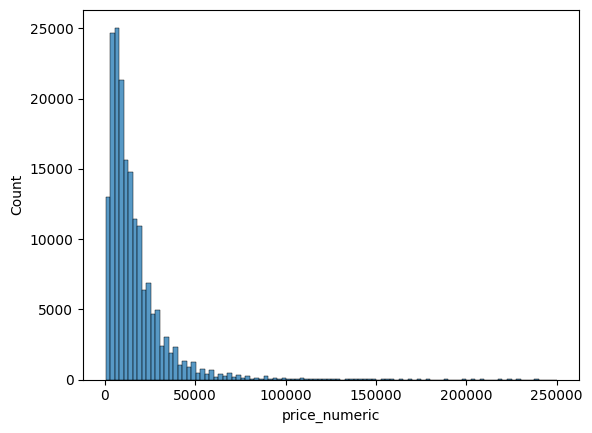

In [10]:
sns.histplot(df['price_numeric'], bins=100)

In [11]:
df['price_numeric'].skew()

np.float64(3.7457113614191857)

# Price outliers
- IQR flagged 10,428 normal cars above 41k and missed the 1 junk prices, so it does not suit skewed prices.
- Used a percentile and common-sense rule instead: kept prices between 500 and 250,000 and removed 1,990 listings (~1%).
- Rows were removed, not capped, because a fake price is still fake.
- Price is still right-skewed (skew 3.75). This will be handled with a log transform .

# lets see for the odometer outliers 

In [12]:
df['odometer'].describe()

count    173448.000000
mean     117206.566291
std       66294.773006
min           1.000000
25%       74000.000000
50%      113000.000000
75%      154000.000000
max      999000.000000
Name: odometer, dtype: float64

In [13]:
(df['odometer'] > 500000).sum()

np.int64(213)

In [14]:
df[df['odometer'] > 500000][['year', 'manufacturer', 'base_model', 'type', 'odometer', 'price_numeric']].head(15)

,year,manufacturer,base_model,type,odometer,price_numeric
2360,2018.0,NaN,international,truck,850183.0,27000.0
5869,2015.0,NaN,maserati,sedan,989000.0,8750.0
9458,2017.0,porsche,macan,SUV,794941.0,17886.0
9572,2012.0,NaN,mack,truck,529547.0,24500.0
12727,2011.0,NaN,mack,truck,986839.0,28950.0
13560,2018.0,NaN,peterbilt,truck,755000.0,53999.0
13870,2008.0,NaN,kenworth,truck,826000.0,120000.0
15390,2016.0,volvo,truck,truck,775000.0,17500.0
17139,2019.0,volvo,truck,truck,993311.0,28000.0
17383,2015.0,volvo,truck,truck,892607.0,22000.0


In [15]:
df['odometer'] = np.where(df['odometer'] > 500000, 500000, df['odometer'])
df['odometer'].describe()

count    173448.000000
mean     116933.221922
std       64045.633067
min           1.000000
25%       74000.000000
50%      113000.000000
75%      154000.000000
max      500000.000000
Name: odometer, dtype: float64

In [16]:
df.loc[(df['odometer'] == 500000) & (df['type'] != 'truck'), 'odometer'] = np.nan
(df['odometer'] == 500000).sum()

np.int64(125)

In [17]:
heavy = ['freightliner', 'kenworth', 'peterbilt', 'mack', 'international', 'hino', 'western']
is_heavy = df['base_model'].isin(heavy) | ((df['manufacturer'] == 'volvo') & (df['base_model'] == 'truck'))
is_heavy.sum()

np.int64(1286)

- Capped odometer at 500,000 miles (fixed limit, so no information from test data is used). 213 listings were affected.
- High readings on semi-trucks are real, but readings like 861,150 on luxury sedans are fake and were set to missing instead.

In [18]:
df = df[~is_heavy]
df.shape

(178449, 20)

- Removed commercial semi-trucks (Freightliner, Kenworth, Peterbilt, Mack, International, Hino, Volvo trucks): they belong to a different market, and this model is for everyday used cars, SUVs, pickups and vans.

# Year Extremes

In [19]:
df['year'].describe()

count    178443.000000
mean       2011.585604
std          12.392207
min        1900.000000
25%        2008.000000
50%        2015.000000
75%        2019.000000
max        2027.000000
Name: year, dtype: float64

In [20]:
(df['year'] < 1950).sum(), (df['year'] < 1970).sum(), (df['year'] < 1990).sum()

(np.int64(880), np.int64(4246), np.int64(9039))

In [21]:
df['decade'] = (df['year'] // 10) * 10
df.groupby('decade')['price_numeric'].agg(['median', 'count'])

,median,count
decade,,
1900.0,999.0,7
1910.0,9997.0,6
1920.0,16000.0,135
1930.0,25000.0,375
1940.0,16500.0,357
1950.0,20000.0,1096
1960.0,19500.0,2270
1970.0,12000.0,2399
1980.0,8500.0,2394


In [22]:
df = df[df['year'] >= 1990]
df = df.drop(columns=['decade'])
df.shape

(169404, 20)

In [23]:
df.groupby((df['year'] // 10) * 10)['price_numeric'].median()

year
1990.0     6500.0
2000.0     5650.0
2010.0    10495.0
2020.0    25364.5
Name: price_numeric, dtype: float64

In [24]:
df.to_csv('cars_no_outliers.csv', index=False)

# Year scope
- Kept cars from 1990 onward and removed about 9,000 older cars (5%). Older cars follow a separate collector market where older means more expensive.
- Limitation: this model is not designed for cars older than 1990, so predictions for classic cars would be unreliable.



# Notebook 04 summary
- Price: kept $500–$250,000. IQR was rejected because it flagged normal trucks and missed the $1 junk prices.
- Odometer: capped at 500,000 miles. Fake high readings on passenger cars were set to missing.
- Removed commercial semi-trucks and pre-1990 cars to keep the model focused on everyday used cars.
- Saved as cars_no_outliers.csv.